In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

In [2]:
def bwf(filter_order,cutoff_frequency,sampling_frequency):

    analog_b,analog_a = butter(filter_order,cutoff_frequency,analog=True,btype='low') #continuous signal + low pass filter

    print(analog_b)
    print(analog_a)

    digital_b,digital_a = bilinear(analog_b,analog_a,sampling_frequency) #perform bilinear 

    return digital_b,digital_a


In [3]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000

In [4]:
digital_b,digital_a = bwf(filter_order,cutoff_frequency,sampling_frequency)

[1.e+12]
[1.00000000e+00 2.61312593e+03 3.41421356e+06 2.61312593e+09
 1.00000000e+12]


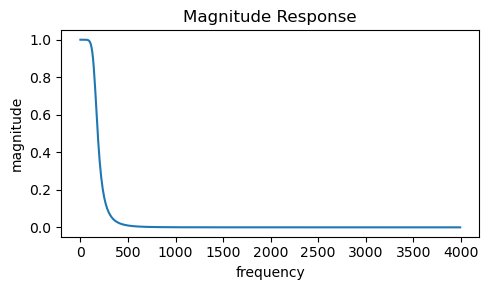

In [5]:
frequency, magnitude_response = freqz(digital_b,digital_a,fs=sampling_frequency)

plt.figure(figsize=(5,3))
plt.plot(frequency,np.abs(magnitude_response))
plt.title("Magnitude Response")
plt.xlabel("frequency")
plt.ylabel("magnitude")
plt.tight_layout()

plt.show()


c:\Users\Priya\anaconda3\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\Priya\anaconda3\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


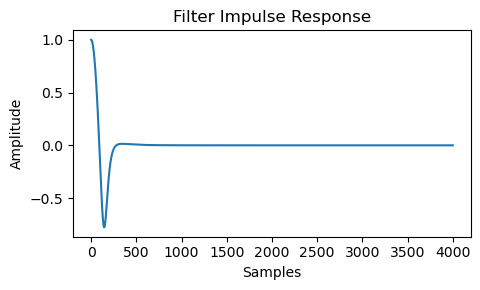

In [6]:
frequency,impulse_response = freqz(digital_b,digital_a,fs=sampling_frequency,worN=4000)

plt.figure(figsize=(5,3))
plt.plot(impulse_response)
plt.title("Filter Impulse Response")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.tight_layout()

plt.show()

In [7]:
def cf(filter_order,cutoff_frequency,sampling_frequency,ripple):

    wc = 2*sampling_frequency*np.tan(np.pi*cutoff_frequency/sampling_frequency)
    analog_b,analog_a = cheby1(filter_order,ripple,wc,analog=True,btype='low') #continuous signal + low pass filter

    print(analog_b)
    print(analog_a)

    digital_b,digital_a = bilinear(analog_b,analog_a,sampling_frequency) #perform bilinear 

    return digital_b,digital_a

In [8]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5

In [9]:
digital_b,digital_a = cf(filter_order,cutoff_frequency,sampling_frequency,ripple)

[6.90358128e+14]
[1.00000000e+00 7.93557405e+03 7.54093239e+07 2.98503630e+11
 7.31264419e+14]


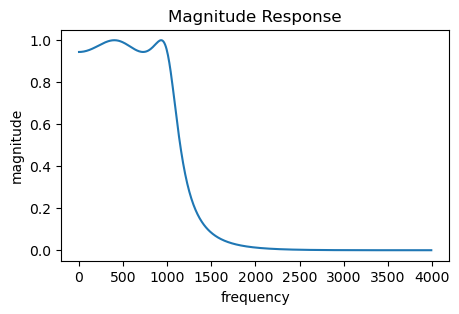

In [10]:
frequency, magnitude_response = freqz(digital_b,digital_a,fs=sampling_frequency)

plt.figure(figsize=(5,3))
plt.plot(frequency,np.abs(magnitude_response))
plt.title("Magnitude Response")
plt.xlabel("frequency")
plt.ylabel("magnitude")

plt.show()


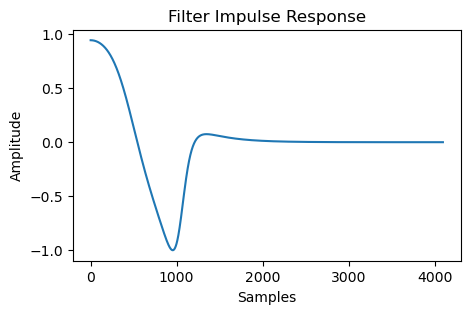

In [11]:
frequency,impulse_response = freqz(digital_b,digital_a,fs=sampling_frequency,worN=4096)

plt.figure(figsize=(5,3))
plt.plot(impulse_response)
plt.title("Filter Impulse Response")
plt.xlabel("Samples")
plt.ylabel("Amplitude")

plt.show()